In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import sys
sys.path.append('../')
from src.ConstitutiveModel import DebyeModel
from src.PlaneWave import PlaneWave

%reload_ext autoreload
%autoreload 2

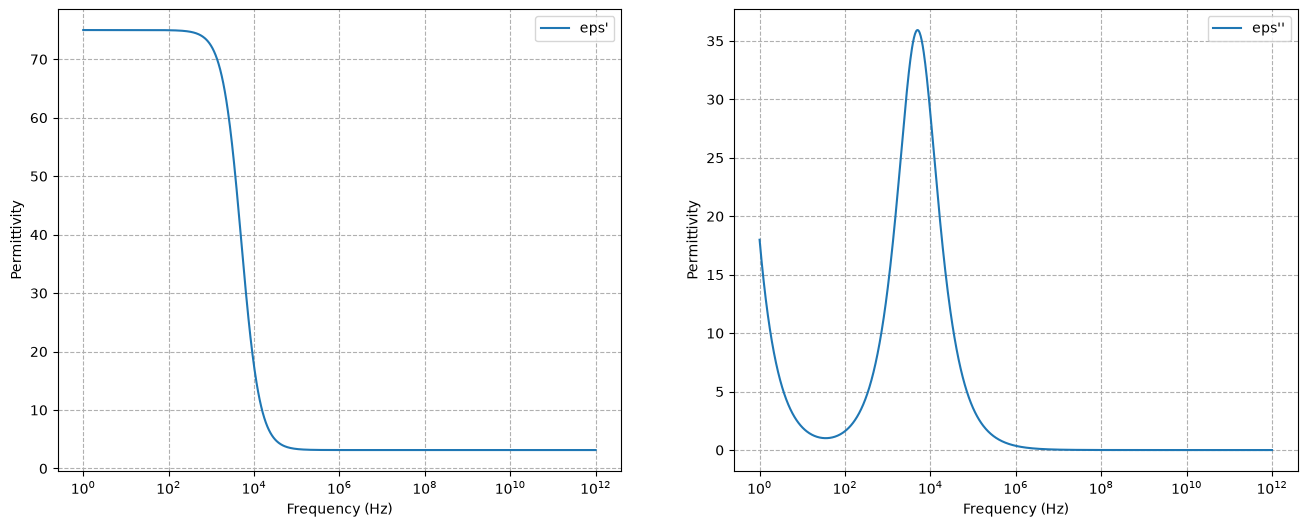

In [3]:
eps_infty = 3.15
eps_s = 75
delta_eps = eps_s - eps_infty
sigma_s = 1e-9
fr = 5e3 
omega_r = 2 * np.pi * fr
tau = 1 / omega_r
eps_0 = 8.854187817e-12
omega = 2 * np.pi * np.logspace(0, 12, 1000)  # frequency range from 1 kHz to 1 GHz
f = omega / (2 * np.pi)

debye_model = DebyeModel(eps_infty, delta_eps, sigma_s, tau)

eps, eps_p, eps_pp = debye_model.debye_single(omega)

plt.figure(figsize=(16, 6))
plt.subplot(1,2,1)
plt.semilogx(f, eps_p, label='eps\'')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Permittivity')
plt.legend()
plt.grid(True, which='both', ls='--')

plt.subplot(1,2,2)
plt.semilogx(f, eps_pp, label='eps\'\'')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Permittivity')
plt.legend()
plt.grid(True, which='both', ls='--')
plt.show()


# Transfer function

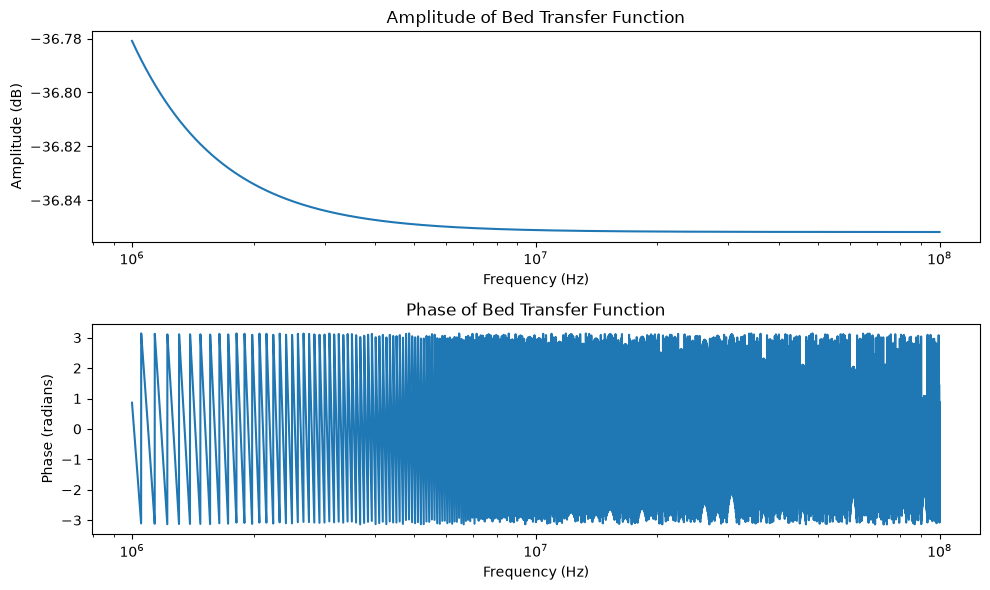

In [4]:
# consider plane wave solution in 1D frequency domain -> diffusive wave
H = 2e3 # ice thickness
mu = 4 * np.pi * 1e-7 # magnetic permeability of free space
sigma = 1e-9
f_range     = np.logspace(6, 8, 10000)  # frequency range from 1 MHz to 1 GHz
omega_range = 2 * np.pi * f_range

# only use the first output (total)
model_specific = lambda omega: debye_model.debye_single(omega)[0]

plane_wave = PlaneWave(
    H = H, 
    mu = mu, 
    sigma = sigma, 
    model = model_specific
)
plane_wave = PlaneWave(
    H = H, 
    mu = mu, 
    sigma = sigma, 
    model = model_specific
)
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.semilogx(f_range, plane_wave.bed_amplitude(omega_range))
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude (dB)')
plt.title('Amplitude of Bed Transfer Function')

plt.subplot(2, 1, 2)
plt.semilogx(f_range, plane_wave.bed_phase(omega_range))
plt.xlabel('Frequency (Hz)')
plt.ylabel('Phase (radians)')
plt.title('Phase of Bed Transfer Function')
plt.tight_layout()
# plt.savefig('../fig/bed_transfer_function.png')
plt.show()

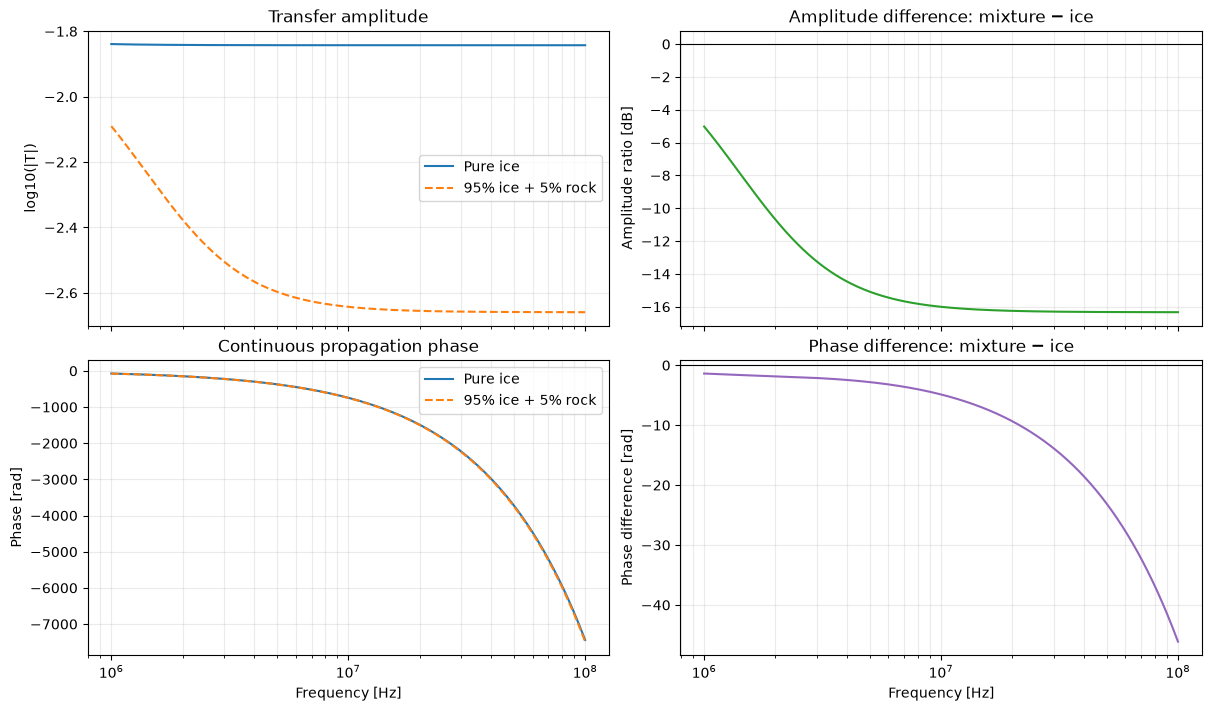

In [5]:
from src.ConstitutiveModel import MixingModel

# These are sensitivity-test values, not a calibrated rock model.
rock_eps_infty = 4.0
rock_eps_s = 8.0
rock_fr = 1e6       # relaxation frequency [Hz]
rock_sigma = 1e-5  # DC conductivity [S/m]

rock_model = DebyeModel(
    eps_infty=rock_eps_infty,
    delta_eps=rock_eps_s - rock_eps_infty,
    sigma_s=rock_sigma,
    tau=1 / (2 * np.pi * rock_fr),
)

# Include your additional ice conductivity in the host material.
def ice_total_model(omega):
    return (
        debye_model.debye_single(omega)[0]
        # - 1j * sigma / (eps_0 * omega)
    )

rock_specific = lambda omega: rock_model.debye_single(omega)[0]

mixing_model = MixingModel(
    inclusion_model=rock_specific,
    host_model=ice_total_model,
    fraction=0.05,  # rock volume fraction
)

mixture_wave = PlaneWave(
    H=H,
    mu=mu,
    sigma=0.0,  # Both constituent conductivities are already included.
    model=mixing_model.maxwell_garnett,
)

# Transfer functions: your existing pure-ice wave and the mixture.
gamma_ice = plane_wave.gamma(omega_range)
gamma_mix = mixture_wave.gamma(omega_range)

# transfer_ice = plane_wave.bed_amplitude(omega_range)
# transfer_mix = mixture_wave.bed_amplitude(omega_range)

# Calculate logarithmic amplitude directly to avoid underflow.
log_amp_ice = -gamma_ice.real * H / np.log(10)
log_amp_mix = -gamma_mix.real * H / np.log(10)

# Continuous phase directly from gamma: no phase-unwrapping ambiguity.
phase_ice = -gamma_ice.imag * H
phase_mix = -gamma_mix.imag * H

delta_amp_db = 20 * (log_amp_mix - log_amp_ice)
delta_phase = phase_mix - phase_ice

fig, axes = plt.subplots(
    2, 2, figsize=(12, 7), sharex=True, constrained_layout=True
)

axes[0, 0].semilogx(f_range, log_amp_ice, label="Pure ice")
axes[0, 0].semilogx(
    f_range, log_amp_mix, "--", label="95% ice + 5% rock"
)
axes[0, 0].set_title("Transfer amplitude")
axes[0, 0].set_ylabel("log10(|T|)")
axes[0, 0].legend()

axes[0, 1].semilogx(f_range, delta_amp_db, color="tab:green")
axes[0, 1].axhline(0, color="black", linewidth=0.8)
axes[0, 1].set_title("Amplitude difference: mixture − ice")
axes[0, 1].set_ylabel("Amplitude ratio [dB]")

axes[1, 0].semilogx(f_range, phase_ice, label="Pure ice")
axes[1, 0].semilogx(
    f_range, phase_mix, "--", label="95% ice + 5% rock"
)
axes[1, 0].set_title("Continuous propagation phase")
axes[1, 0].set_ylabel("Phase [rad]")
axes[1, 0].legend()

axes[1, 1].semilogx(f_range, delta_phase, color="tab:purple")
axes[1, 1].axhline(0, color="black", linewidth=0.8)
axes[1, 1].set_title("Phase difference: mixture − ice")
axes[1, 1].set_ylabel("Phase difference [rad]")

for ax in axes.flat:
    ax.grid(True, which="both", alpha=0.25)

for ax in axes[1, :]:
    ax.set_xlabel("Frequency [Hz]")

plt.savefig('../fig/pureice_vs_mixture.png')
plt.show()



# Layered model

In [21]:
from src.LayeredColumn import LayeredColumn
# add LayeredColumn


# define constitutive models
omega_run  = 2 * np.pi * np.logspace(6, 9, 1000)  # frequency range from 1 Mhz to 1 GHz
omega_plot = 2 * np.pi * np.array([1e6, 1e7, 1e8, 1e9]) # for plotting
f      = omega_run / (2 * np.pi)
f_plot = omega_plot / (2 * np.pi)

# ------------- clean ice ---------------
ice_eps_infty = 3.15
ice_eps_s = 75
ice_delta_eps = ice_eps_s - ice_eps_infty
ice_sigma_s = 1e-9
ice_fr = 5e3 
ice_omega_r = 2 * np.pi * ice_fr
ice_tau = 1 / ice_omega_r

clean_ice_model = DebyeModel(
    eps_infty=ice_eps_infty,
    delta_eps=ice_delta_eps,
    sigma_s=ice_sigma_s,
    tau=ice_tau)
clean_ice_fn = lambda omega: clean_ice_model.debye_single(omega)[0]

# ------------- debris ladden ice ---------------
# These are sensitivity-test values, not a calibrated rock model.
rock_eps_infty = 6.0
rock_eps_s = 10.0
rock_fr = 1e6       # relaxation frequency [Hz]
rock_sigma = 1e-5  # DC conductivity [S/m]
rock_tau = 1 / (2 * np.pi * rock_fr)

rock_model = DebyeModel(
    eps_infty=rock_eps_infty,
    delta_eps=rock_eps_s - rock_eps_infty,
    sigma_s=rock_sigma,
    tau=rock_tau,
)

rock_fn = lambda omega: rock_model.debye_single(omega)[0]

# mixture model
mixing_model = MixingModel(
    inclusion_model=rock_fn,
    host_model=clean_ice_fn,
    fraction=0.05,  # rock volume fraction
)

# --------------- bedrock ---------------
# this re-uses rock_fn
bedrock_fn = rock_fn

Surface: 0, Base: 4100.0 m below surface
Layer 1: s = 0, b = 2000.0
Layer 2: s = 2000.0, b = 2100.0
Layer 3: s = 2100.0, b = 4100.0


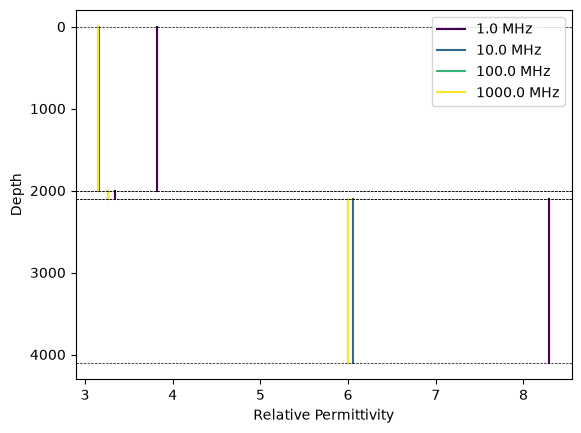

In [54]:
clean_ice = PlaneWave(
    H = H, 
    s = 0,
    mu = mu, 
    sigma = 1e-4, 
    model = clean_ice_fn
)
dirty_ice = PlaneWave(
    H = 100,
    s = clean_ice.b,
    mu=mu,
    sigma=0.0,  
    model=mixing_model.maxwell_garnett,
)
bed = PlaneWave(
    H = H,
    s = dirty_ice.b,
    mu = mu,
    sigma = sigma,
    model = bedrock_fn
)
waves = [clean_ice, dirty_ice, bed]
layered_column = LayeredColumn(waves)
layered_column.show_geometry()
layered_column.show_permittivity(omega_plot)

In [55]:
R = layered_column.reflection_coefficient(omega_plot)
T = layered_column.transmission_coefficient(omega_plot)
print(f"Reflection Coefficient R:{np.abs(R)}")
print(f"Transmission Coefficient T:{np.abs(T)}")

Reflection Coefficient R:[[0.12469398 0.01574719 0.0087394  0.00864063]
 [0.22623293 0.15391092 0.15130633 0.15127954]]
Transmission Coefficient T:[[1.04077812 0.9918954  0.99136572 0.99136043]
 [0.77713336 0.84675408 0.8487007  0.84872053]]


Reference round-trip delay: 1.205 µs


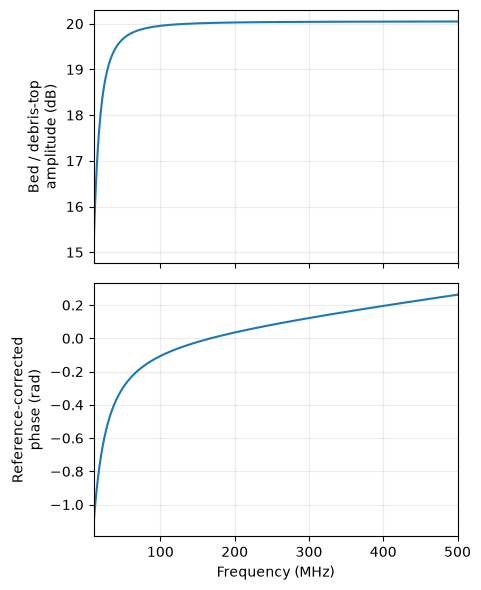

In [56]:
f_mhz = np.linspace(10.0, 500.0, 20_001)
omega = 2.0 * np.pi * f_mhz * 1e6

spec = layered_column.spectral_ratio(omega, n_ref=1.8059)
print(f"Reference round-trip delay: {spec['tau_ref_s'] * 1e6:.3f} µs")

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(5, 6))

ax[0].plot(f_mhz, spec["amplitude_db"])
ax[0].set_ylabel("Bed / debris-top\namplitude (dB)")

ax[1].plot(f_mhz, spec["phase_corrected_rad"])
ax[1].set_ylabel("Reference-corrected\nphase (rad)")
ax[1].set_xlabel("Frequency (MHz)")
ax[1].set_xlim(10, 500)

for a in ax:
    a.grid(alpha=0.25)

fig.tight_layout()
plt.savefig("../fig/spectral_ratio.png")
plt.show()


# Adding thermal influence

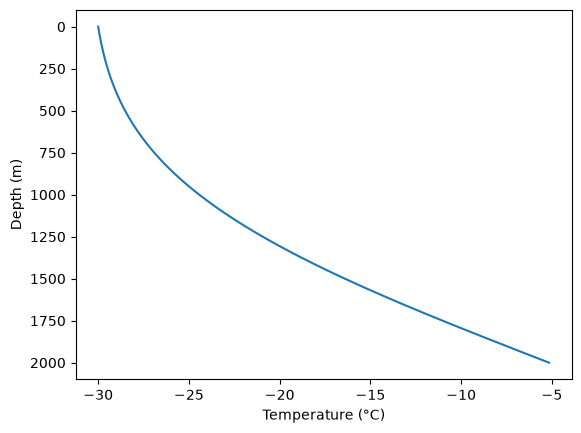

In [61]:
from src.Thermal import robin_temperature


z = np.linspace(0, 2000, 501)
T = robin_temperature(
    z, H=2000, T_surface=-30.0,
    accumulation_m_per_yr=0.10, q_b=0.050,
)

plt.plot(T, z)
plt.gca().invert_yaxis()
plt.xlabel("Temperature (°C)")
plt.ylabel("Depth (m)")
plt.show()